# Phase II (AI-aided): kNN in embedding space

Claims and decision rules: `claims.md`. Data: `results/akidanet_imagenetc.parquet` (card run; predictions identical to `results_card/predictions.csv`). Run from `phase2/ai-aided/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score

sys.path.insert(0, str(Path.cwd()))
from aiv2 import knn
from aiv2.stats import auroc_ci, auroc_diff_ci

FIG = knn.ROOT / "figures" / "phase2_ai"
FIG.mkdir(parents=True, exist_ok=True)
COL = {"fog": "#4C78A8", "gaussian_noise": "#E45756", "contrast": "#54A24B"}
pd.set_option("display.width", 160)

d = knn.load()
f = knn.per_image(d)          # neighbourhood features per image and condition
print(f"{len(f)} rows, k = {knn.K}, sink = class with >= {knn.SINK_SHARE:.0%} of CNN answers")


30000 rows, k = 15, sink = class with >= 5% of CNN answers


## 0. Embedding sanity check

In [2]:
# Is the embedding semantic at all? Each class has 2 images per condition, so at most one
# same-label neighbour exists. Chance of it being among 15 of 1999: 15/1999.
chk = f.groupby(["corruption", "severity"]).label_nbr.mean().unstack() * knn.K
chk.columns = [f"sev {s}" for s in chk.columns]
print("Share of images whose same-class partner is among its 15 neighbours")
print(chk.round(3).to_string())
print(f"chance: {knn.K / 1999:.4f}")


Share of images whose same-class partner is among its 15 neighbours
                sev 1  sev 2  sev 3  sev 4  sev 5
corruption                                       
contrast        0.245  0.206  0.145  0.075  0.048
fog             0.240  0.213  0.176  0.144  0.104
gaussian_noise  0.208  0.137  0.086  0.056  0.038
chance: 0.0075


## C2. Does corruption collapse the embedding into sinks?

spread falls monotonically: {'fog': True, 'gaussian_noise': True, 'contrast': True}
    corruption  severity  n_sink   sink   rest      p
      contrast         3     171 0.2876 0.3108 0.0000
      contrast         4     331 0.1963 0.1907 0.9977
      contrast         5     662 0.0526 0.1018 0.0000
           fog         4     258 0.2700 0.3493 0.0000
           fog         5     599 0.2050 0.2915 0.0000
gaussian_noise         2     133 0.2808 0.2880 0.1464
gaussian_noise         3     813 0.1700 0.1949 0.0000
gaussian_noise         4    1426 0.1034 0.1261 0.0000
gaussian_noise         5    1683 0.0554 0.0806 0.0000


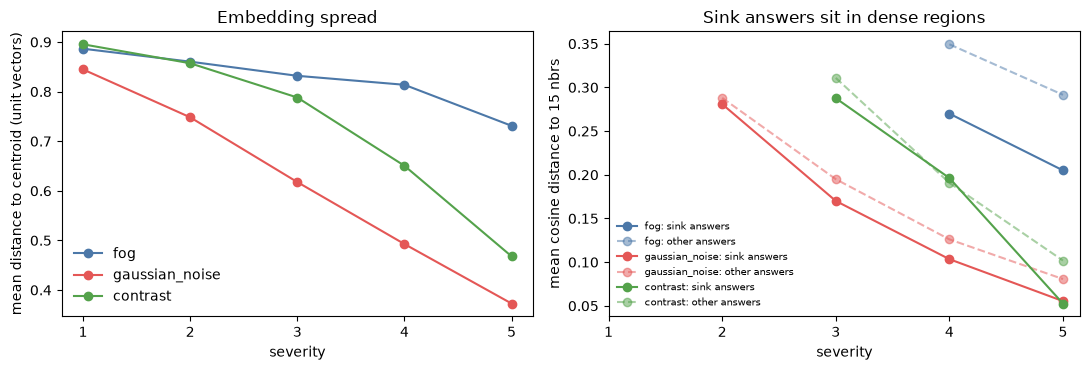

In [3]:
# C2 (a): embedding spread per condition. (b): sinks are dense regions.
sp = knn.spread(d)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for c in knn.CORRUPTIONS:
    s = sp[sp.corruption == c]
    ax[0].plot(s.severity, s.spread, "o-", color=COL[c], label=c)
ax[0].set(xlabel="severity", ylabel="mean distance to centroid (unit vectors)",
          title="Embedding spread", xticks=knn.SEVERITIES)
ax[0].legend(frameon=False)

rows = []
for (c, s), g in f.groupby(["corruption", "severity"]):
    if g.in_sink.any():
        a, b = g.knn_dist[g.in_sink], g.knn_dist[~g.in_sink]
        rows.append(dict(corruption=c, severity=s, n_sink=len(a), sink=a.mean(), rest=b.mean(),
                         p=mannwhitneyu(a, b, alternative="less").pvalue))
dense = pd.DataFrame(rows)
for c in knn.CORRUPTIONS:
    t = dense[dense.corruption == c]
    ax[1].plot(t.severity, t.sink, "o-", color=COL[c], label=f"{c}: sink answers")
    ax[1].plot(t.severity, t.rest, "o--", color=COL[c], alpha=.5, label=f"{c}: other answers")
ax[1].set(xlabel="severity", ylabel="mean cosine distance to 15 nbrs",
          title="Sink answers sit in dense regions", xticks=knn.SEVERITIES)
ax[1].legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(FIG / "c2_spread_and_sink_density.png", dpi=150)
mono = {c: bool(np.all(np.diff(sp[sp.corruption == c].sort_values("severity").spread) < 0))
        for c in knn.CORRUPTIONS}
print("spread falls monotonically:", mono)
print(dense.round(4).to_string(index=False))


## C1. Are disagreements near-ties?

    corruption  severity  n_dis  auc_conf    lo    hi  cnn_support  snn_support  rand_support  diff  d_lo  d_hi
      contrast         1    419     0.799 0.777 0.820        0.041        0.036         0.003 0.033 0.027 0.039
      contrast         2    497     0.770 0.748 0.792        0.051        0.043         0.005 0.038 0.031 0.045
      contrast         3    594     0.741 0.719 0.763        0.081        0.062         0.015 0.047 0.037 0.056
      contrast         4    682     0.730 0.710 0.753        0.123        0.106         0.038 0.068 0.057 0.079
      contrast         5    742     0.671 0.646 0.694        0.173        0.158         0.053 0.106 0.090 0.121
           fog         1    424     0.778 0.754 0.802        0.040        0.036         0.003 0.033 0.028 0.039
           fog         2    516     0.748 0.726 0.771        0.048        0.054         0.005 0.050 0.042 0.057
           fog         3    576     0.751 0.728 0.772        0.067        0.055         0.010 0.045 0.03

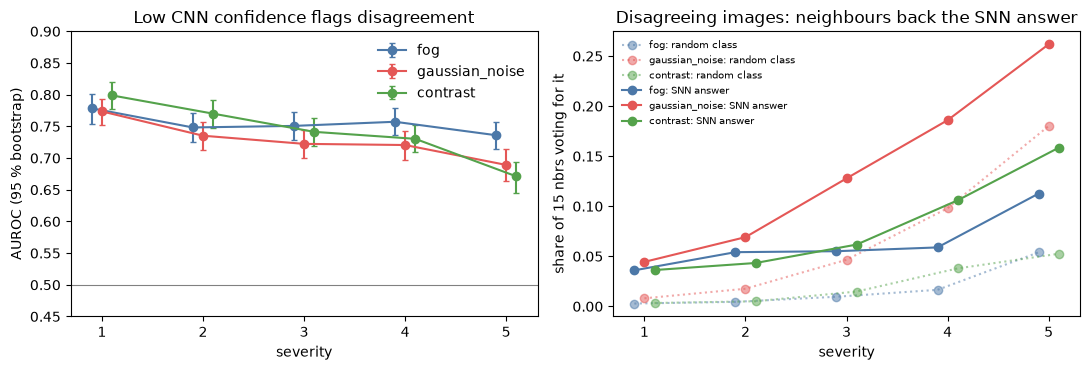

In [4]:
# C1: disagreements are near-ties.
# (a) low CNN confidence predicts disagreement. (b) the SNN answer is supported by the CNN's
# own neighbourhood more than a frequency-matched random class.
rows = []
for (c, s), g in f.groupby(["corruption", "severity"]):
    a, lo, hi = auroc_ci(g.disagree, -g.cnn_conf)
    dis = g[g.disagree]
    diff = (dis.snn_support - dis.rand_support).values
    rng = np.random.default_rng(0)
    bs = [rng.choice(diff, len(diff)).mean() for _ in range(1000)]
    rows.append(dict(corruption=c, severity=s, n_dis=len(dis), auc_conf=a, lo=lo, hi=hi,
                     cnn_support=dis.consensus.mean(),
                     snn_support=dis.snn_support.mean(), rand_support=dis.rand_support.mean(),
                     diff=diff.mean(), d_lo=np.percentile(bs, 2.5), d_hi=np.percentile(bs, 97.5)))
c1 = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for i, c in enumerate(knn.CORRUPTIONS):
    t = c1[c1.corruption == c]
    x = t.severity + (i - 1) * .1
    ax[0].errorbar(x, t.auc_conf, [t.auc_conf - t.lo, t.hi - t.auc_conf], fmt="o-",
                   color=COL[c], capsize=2, label=c)
    ax[1].errorbar(x, t.snn_support, fmt="o-", color=COL[c], label=f"{c}: SNN answer")
    ax[1].plot(x, t.rand_support, "o:", color=COL[c], alpha=.5, label=f"{c}: random class")
ax[0].axhline(.5, color="grey", lw=.8)
ax[0].set(xlabel="severity", ylabel="AUROC (95 % bootstrap)", ylim=(.45, .9),
          title="Low CNN confidence flags disagreement", xticks=knn.SEVERITIES)
ax[0].legend(frameon=False)
ax[1].set(xlabel="severity", ylabel="share of 15 nbrs voting for it",
          title="Disagreeing images: neighbours back the SNN answer", xticks=knn.SEVERITIES)
ax[1].legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(FIG / "c1_near_ties.png", dpi=150)
print(c1.round(3).to_string(index=False))


## C3. Confidence vs neighbourhood, and both combined

fog: Spearman(severity, cons - conf) = +1.00
gaussian_noise: Spearman(severity, cons - conf) = +1.00
contrast: Spearman(severity, cons - conf) = +1.00
    corruption  severity  auc_conf  auc_cons  cons_minus_conf     lo     hi  auc_both_cv  auc_cons_no_sink  both_ge_best
      contrast         1     0.799     0.542           -0.257 -0.289 -0.226        0.798             0.542         False
      contrast         2     0.770     0.545           -0.225 -0.255 -0.194        0.768             0.545         False
      contrast         3     0.741     0.572           -0.169 -0.197 -0.138        0.738             0.567         False
      contrast         4     0.730     0.648           -0.082 -0.111 -0.052        0.730             0.625         False
      contrast         5     0.671     0.679            0.008 -0.023  0.042        0.714             0.657          True
           fog         1     0.778     0.539           -0.240 -0.272 -0.207        0.777             0.539         False
  

/var/folders/l0/7y17nx9n1yzgd1wwwv_sqpjc0000gn/T/ipykernel_72636/2922896085.py:34: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  c3["both_ge_best"] = c3.auc_both_cv >= c3[["auc_conf", "auc_cons"]].max(1) - 1e-9


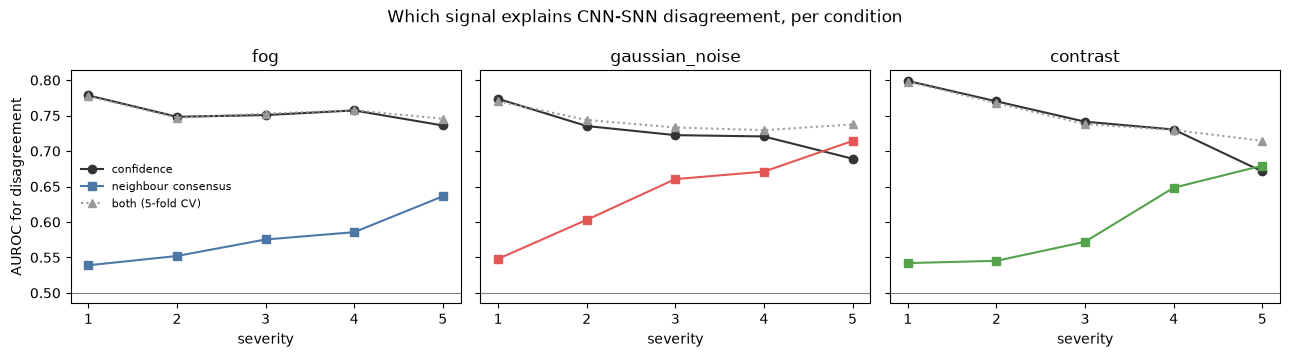

In [5]:
# C3: the two signals trade places with severity; combining them helps.
rows = []
for (c, s), g in f.groupby(["corruption", "severity"]):
    y = g.disagree.values
    X = np.column_stack([g.cnn_conf, g.consensus, g.knn_dist])
    a_conf = roc_auc_score(y, -g.cnn_conf)
    a_cons = roc_auc_score(y, -g.consensus)
    dd, lo, hi = auroc_diff_ci(y, -g.cnn_conf, -g.consensus)
    p = cross_val_predict(LogisticRegression(max_iter=1000), X[:, :2], y, cv=5,
                          method="predict_proba")[:, 1]
    ns = g[~g.in_sink]  # confound check: is consensus only "the image fell into a sink"?
    rows.append(dict(corruption=c, severity=s, auc_conf=a_conf, auc_cons=a_cons,
                     cons_minus_conf=dd, lo=lo, hi=hi, auc_both_cv=roc_auc_score(y, p),
                     auc_cons_no_sink=roc_auc_score(ns.disagree, -ns.consensus)))
c3 = pd.DataFrame(rows)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, c in zip(axs, knn.CORRUPTIONS):
    t = c3[c3.corruption == c]
    ax.plot(t.severity, t.auc_conf, "o-", color="#333", label="confidence")
    ax.plot(t.severity, t.auc_cons, "s-", color=COL[c], label="neighbour consensus")
    ax.plot(t.severity, t.auc_both_cv, "^:", color="#999", label="both (5-fold CV)")
    ax.axhline(.5, color="grey", lw=.8)
    ax.set(title=c, xlabel="severity", xticks=knn.SEVERITIES)
axs[0].set_ylabel("AUROC for disagreement")
axs[0].legend(frameon=False, fontsize=8)
fig.suptitle("Which signal explains CNN-SNN disagreement, per condition")
fig.tight_layout()
fig.savefig(FIG / "c3_signals_trade_places.png", dpi=150)
for c in knn.CORRUPTIONS:
    t = c3[c3.corruption == c]
    r = spearmanr(t.severity, t.cons_minus_conf)
    print(f"{c}: Spearman(severity, cons - conf) = {r.statistic:+.2f}")
c3["both_ge_best"] = c3.auc_both_cv >= c3[["auc_conf", "auc_cons"]].max(1) - 1e-9
print(c3.round(3).to_string(index=False))


## Maps

/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/yoshimartodihardjo/jku-ai-vis-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


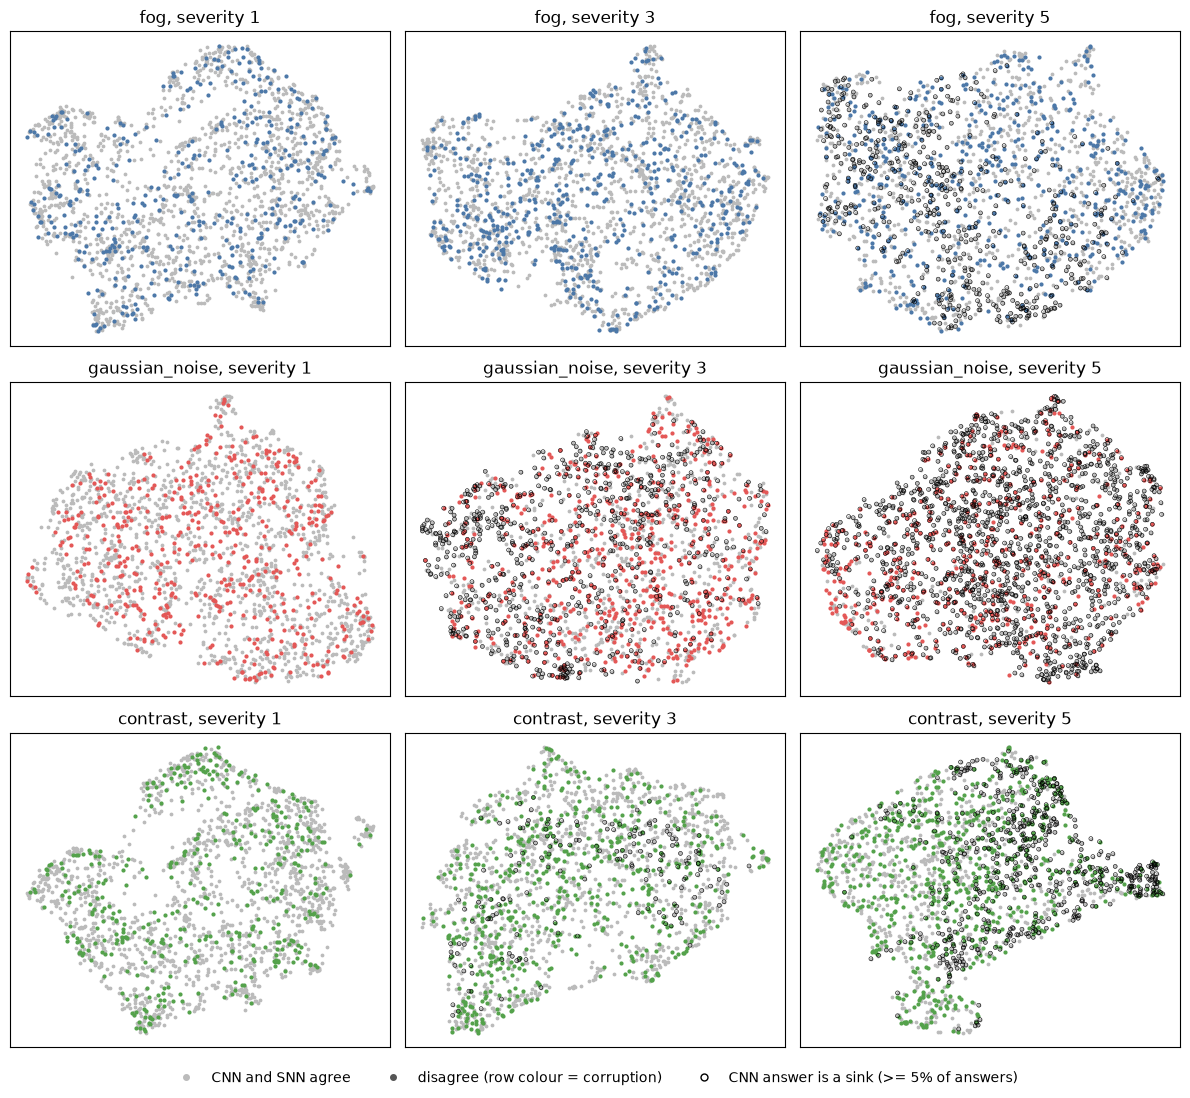

In [6]:
# Map of the embedding for three severities per corruption (UMAP on the 512-d vectors of
# one condition at a time, cosine, n_neighbors=15, min_dist=0.1, seed 0). Positions are not
# comparable between panels, and cluster sizes mean nothing (Lecture 03).
import umap
from matplotlib.lines import Line2D

fig, axs = plt.subplots(3, 3, figsize=(12, 11))
maps = {}
for i, c in enumerate(knn.CORRUPTIONS):
    for j, s in enumerate([1, 3, 5]):
        g = f[(f.corruption == c) & (f.severity == s)]
        E = knn.unit(np.vstack(d.loc[g.index, "embedding"].values))
        xy = umap.UMAP(n_neighbors=15, min_dist=.1, metric="cosine",
                       random_state=0).fit_transform(E)
        maps[(c, s)] = (g, xy)
        ax = axs[i, j]
        ax.scatter(*xy[g.agree.values].T, s=3, c="#bbb", label="agree")
        ax.scatter(*xy[g.disagree.values].T, s=4, c=COL[c], label="disagree")
        sk = g.in_sink.values
        if sk.any():
            ax.scatter(*xy[sk].T, s=8, facecolors="none", edgecolors="k", lw=.4,
                       label="CNN answer is a sink")
        ax.set(title=f"{c}, severity {s}", xticks=[], yticks=[])
handles = [Line2D([], [], ls="", marker="o", ms=4, color="#bbb", label="CNN and SNN agree"),
           Line2D([], [], ls="", marker="o", ms=4, color="#555",
                  label="disagree (row colour = corruption)"),
           Line2D([], [], ls="", marker="o", ms=5, mfc="none", mec="k",
                  label=f"CNN answer is a sink (>= {knn.SINK_SHARE:.0%} of answers)")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, .03, 1, 1))
fig.savefig(FIG / "umap_embedding_agreement.png", dpi=150)


In [7]:
# Interactive version for exploration: hover shows the image and both answers.
# Saved as HTML next to the figures; open it in a browser.
import plotly.express as px
from plotly.subplots import make_subplots

H = pd.read_csv(knn.ROOT / "phase1" / "ai-aided" / "aiv" / "imagenet_hierarchy.csv")
name = H.set_index("label").name
panels = [("gaussian_noise", 3), ("contrast", 5), ("fog", 5)]
fig = make_subplots(rows=1, cols=3, subplot_titles=[f"{c} {s}" for c, s in panels])
for k, (c, s) in enumerate(panels, 1):
    g, xy = maps[(c, s)]
    t = pd.DataFrame(dict(x=xy[:, 0], y=xy[:, 1], image=g.image_id.values,
                          true=name[g.true_label].values, cnn=name[g.cnn_pred].values,
                          snn=name[g.akida_pred].values, conf=g.cnn_conf.round(3).values,
                          consensus=g.consensus.values,
                          status=np.where(g.agree, "agree", "disagree")))
    sc = px.scatter(t, x="x", y="y", color="status", hover_data=["image", "true", "cnn", "snn",
                    "conf", "consensus"], color_discrete_map={"agree": "#bbb",
                    "disagree": COL[c]})
    for tr in sc.data:
        tr.showlegend = k == 1
        fig.add_trace(tr, row=1, col=k)
fig.update_traces(marker_size=4)
fig.update_xaxes(visible=False)
fig.update_yaxes(visible=False)
fig.update_layout(height=450, width=1300, title="Embedding maps, hover for details")
fig.write_html(FIG / "umap_interactive.html", include_plotlyjs="cdn")
print("wrote", FIG / "umap_interactive.html")


wrote /Users/yoshimartodihardjo/jku-ai-vis-2026/figures/phase2_ai/umap_interactive.html


## Findings (Phase II, kNN in embedding space)

Run: `results/akidanet_imagenetc.parquet` (AKD1000 card run, 2000 images x 15 conditions; its
predictions equal `results_card/predictions.csv` on all 30 000 rows). Cosine kNN, k = 15,
neighbours searched inside one corruption x severity. 95 % bootstrap intervals (1000
resamples over images). All headline numbers were recomputed by `verify_numbers.py` (brute-force
numpy, rank AUROC) and match.

**What the embedding is.** 512 signed values per image and condition, most likely the quantized
Keras model's penultimate features (the export script is not in the repo; see `TODO-yoshi.md`).
So this view explains where the *shared CNN representation* is ambiguous, not what the chip does
internally. It is semantic: the other image of the same class is among the 15 neighbours for
21–25 % of images at severity 1, against 0.75 % by chance. That falls to 4–10 % at severity 5.

1. **C1, disagreements are near-ties: supported.**
   - Low CNN confidence flags disagreement in every condition: AUROC 0.77–0.80 at severity 1,
     0.67–0.74 at severity 5; every interval is above 0.5.
   - On images where the two models disagree, the CNN's neighbours vote for the **SNN's answer
     almost as often as for the CNN's own answer** (severity 1: 0.036 vs 0.041 of neighbours,
     contrast; 0.036 vs 0.040, fog; 0.044 vs 0.049, noise). A frequency-matched random class gets
     0.003–0.008. The paired difference SNN-answer − random is above 0 in all 15 conditions
     (smallest: fog 1 and contrast 1, +0.033, lower bounds +0.027 to +0.028).
   - Reading: the SNN does not invent new answers. It picks the class that was already the
     runner-up in the CNN's own representation. This is the near-tie mechanism Phase I guessed
     for H3, now tested.
2. **C2, corruption collapses the embedding into sinks: partly supported.**
   - (a) Spread (mean distance of unit vectors to their centroid) falls monotonically with
     severity for all three corruptions: noise 0.85 → 0.37, contrast 0.90 → 0.47, fog 0.89 → 0.73.
     Fog collapses least, matching its flat agreement curve in Phase I.
   - (b) Sink answers sit in denser regions in 7 of 9 conditions that have a sink (for example
     contrast 5: mean kNN distance 0.053 vs 0.102; noise 5: 0.055 vs 0.081; p < 0.001). The two
     exceptions are contrast 4 (0.196 vs 0.191, p ≈ 1.0) and noise 2 (0.281 vs 0.288, p = 0.15).
     The decision rule asked for every condition, so the verdict is partial.
   - Sinks matter for agreement: images whose CNN answer is a sink agree 73–83 %, the rest
     48–71 %. At noise 5, 84 % of CNN answers are sinks.
3. **C3, the two signals trade places with severity: partly supported.**
   - (a) AUROC(consensus) − AUROC(confidence) rises with severity in every corruption (Spearman
     +1.0, n = 5 each). At severity 1 confidence wins by 0.23–0.26. At severity 5 consensus has
     caught up: noise 5 +0.025 [−0.004, +0.054], contrast 5 +0.008 [−0.023, +0.042]. Neither
     interval excludes 0, so "consensus overtakes confidence" is **not** shown. Fog never gets
     close (−0.10 at severity 5).
   - (b) A cross-validated logistic model on both signals beats the better single one in 8 of 15
     conditions, never at severity 1 (noise 5: 0.738 vs 0.714; contrast 5: 0.714 vs 0.679).
     Where it loses, it is 0.000–0.004 below confidence alone, which is fold noise; the rule "≥ in every condition"
     fails in 7 of 15 (contrast 1–4, fog 1–2, noise 1).
   - Confound check: consensus is not just "the image fell into a sink". On non-sink images only,
     its AUROC is still 0.58–0.66 at severities 4–5.
   - Reading: at mild corruption, divergence is a *decision-level* tie (two close logits, and 4-bit
     rounding on the chip tips it). At heavy corruption it also becomes a *representation-level*
     effect: the image lands in a crowded, mixed region of the embedding, where many classes
     compete.
4. **Map views** (`umap_embedding_agreement.png`, `umap_interactive.html` with hover on image id,
   true class, both answers, confidence, consensus). At severity 1 disagreements are scattered
   with no region of their own. At contrast 5 and noise 5 the sink answers form one dense side of
   the map. Cluster sizes and distances between panels carry no meaning.

**Links to the other techniques.** Layer-wise sparsity (L1 in `claims.md`) is still blocked on the
per-image export. Once it is in, the test is: within one condition, do disagreeing images (and
low-consensus images) show lower activity in the last layers than agreeing ones?

Limits: one embedding source of unknown exact layer; 2 images per class; the same 2000 images
appear in all 15 conditions, so conditions are not independent; CNN confidence and the embedding
both come from the CNN side, so neither describes the chip's internal state directly.
